# Module 03: Magnetic Field Laboratory

## Introduction & Learning Objectives
Unlike electrostatic fields, which diverge from positive charges and terminate on negative charges ($\nabla \cdot \mathbf{E} = \rho / \varepsilon_0$), **magnetostatic fields** $\mathbf{B}(\mathbf{r})$ generated by steady electric currents have zero divergence ($\nabla \cdot \mathbf{B} = 0$) and always form closed loops around current paths ($\nabla \times \mathbf{B} = \mu_0 \mathbf{J}$).

**Learning Objectives:**
1. Compute and visualize the magnetic flux density $\mathbf{B}(\mathbf{r})$ around an infinitely long straight current-carrying wire using the Biot–Savart / Ampère law and the **right-hand rule**.
2. Compute the exact 2D off-axis magnetic field of a **circular current loop** of radius $R$ using complete elliptic integrals and verify its axial profile against the analytical on-axis Biot–Savart equation.
3. Compare a finite circular current loop with an idealized **point magnetic dipole** ($1/r^3$), understanding why a point dipole is only a far-field approximation ($r \gg R$) and not an exact model of the interior of a physical bar magnet.
4. Distinguish steady magnetostatic fields ($\partial \mathbf{B}/\partial t = \mathbf{0}$) from time-varying propagating electromagnetic waves.

---

## Physical Models, Units & Equations

1. **Long Straight Wire along the $z$-axis**:
   $$B(r) = \frac{\mu_0 |I|}{2\pi r}, \qquad \mathbf{B}(x, y) = \frac{\mu_0 I}{2\pi r^2}(-y\,\hat{\mathbf{x}} + x\,\hat{\mathbf{y}})$$
   where $\mu_0 = 4\pi \times 10^{-7}\ \text{H/m}$ (CODATA 2022: $1.25663706127 \times 10^{-6}\ \text{H/m}$), $I$ is current in amperes ($\text{A}$), and $r = \sqrt{x^2 + y^2}$ in meters ($\text{m}$).
   - **Right-Hand Rule**: Point the right thumb along the current $I$. For $I > 0$ ($+\hat{\mathbf{z}}$, out of the page, $\odot$), fingers curl **counterclockwise** in the $x$-$y$ plane. For $I < 0$ ($-\hat{\mathbf{z}}$, into the page, $\otimes$), fingers curl **clockwise**.

2. **Circular Current Loop of Radius $R$ in the $x$-$y$ Plane**:
   - Exact off-axis field $(B_x, B_z)$ in the $x$-$z$ plane is computed via complete elliptic integrals $K(m)$ and $E(m)$.
   - Along the central $z$-axis ($x = 0$), this simplifies exactly to:
     $$B_z(0, z) = \frac{\mu_0 I R^2}{2(R^2 + z^2)^{3/2}}$$

3. **Point Magnetic Dipole (Far-Field Approximation)**:
   $$\mathbf{B}_{\text{dipole}}(\mathbf{r}) = \frac{\mu_0}{4\pi}\frac{3(\mathbf{m}\cdot\hat{\mathbf{r}})\hat{\mathbf{r}} - \mathbf{m}}{r^3}$$

In [1]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))

import numpy as np
import matplotlib.pyplot as plt

from invisible_physics import (
    MU_0,
    apply_scientific_style,
    create_coordinate_grid,
    magnetic_field_circular_loop_on_axis,
    magnetic_field_circular_loop_xz,
    magnetic_field_dipole_2d,
    magnetic_field_straight_wire_1d,
    magnetic_field_straight_wire_2d,
    plot_magnetic_field_2d,
    verify_circular_loop_on_axis,
)

apply_scientific_style()
print(f"Vacuum magnetic permeability mu_0 = {MU_0:.6e} H/m (T·m/A)")

Vacuum magnetic permeability mu_0 = 1.256637e-06 H/m (T·m/A)


---
## 1. Straight Current-Carrying Wire & The Right-Hand Rule

Let us compare two wires carrying $I = +15\ \text{A}$ (out of page $\odot$) and $I = -15\ \text{A}$ (into page $\otimes$), alongside the $1/r$ radial decay profile.

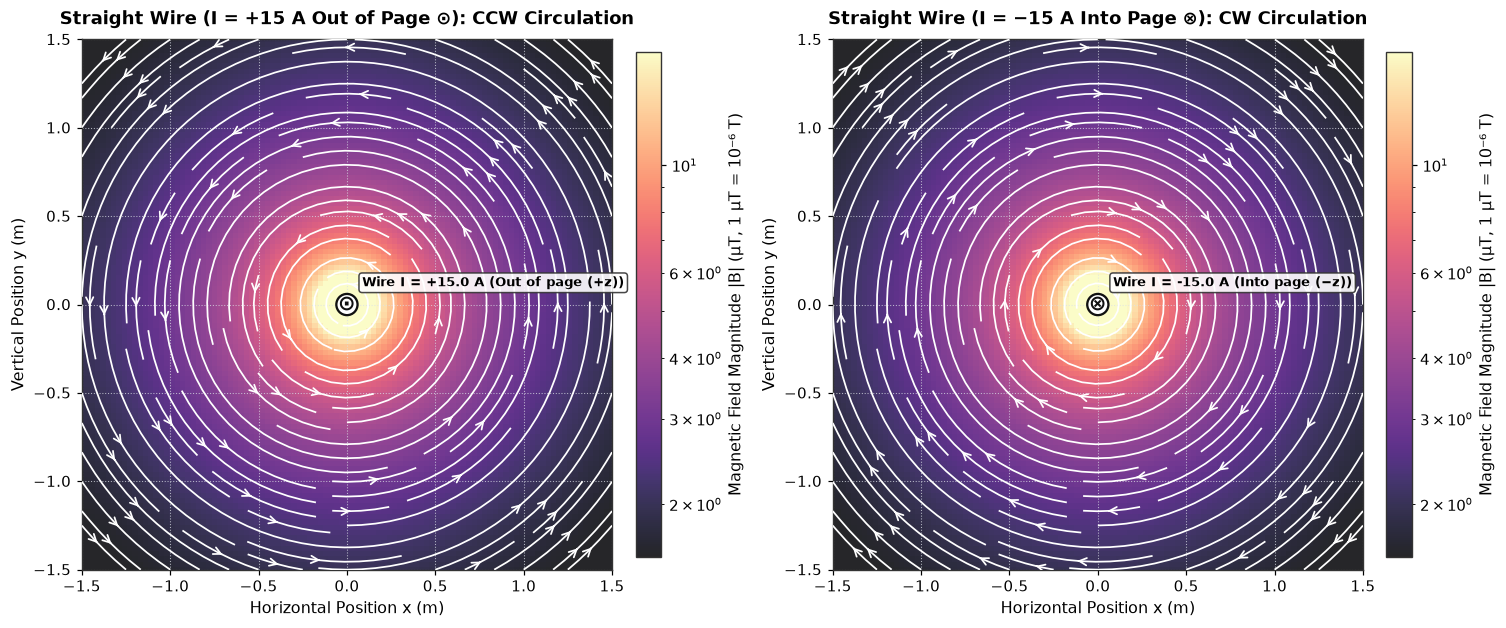

Distance r = 0.10 m  ->  |B| =  30.00 μT
Distance r = 0.20 m  ->  |B| =  15.00 μT
Distance r = 0.50 m  ->  |B| =   6.00 μT
Distance r = 1.00 m  ->  |B| =   3.00 μT
Distance r = 1.50 m  ->  |B| =   2.00 μT


In [2]:
X, Y = create_coordinate_grid((-1.5, 1.5), (-1.5, 1.5), n_points=101)

wire_pos = magnetic_field_straight_wire_2d(X, Y, current_amps=+15.0, r_min=0.06)
wire_neg = magnetic_field_straight_wire_2d(X, Y, current_amps=-15.0, r_min=0.06)

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.6), constrained_layout=True)
plot_magnetic_field_2d(
    wire_pos, ax=axes[0], current_amps=+15.0,
    title="Straight Wire (I = +15 A Out of Page ⊙): CCW Circulation"
)
plot_magnetic_field_2d(
    wire_neg, ax=axes[1], current_amps=-15.0,
    title="Straight Wire (I = −15 A Into Page ⊗): CW Circulation"
)
plt.show()

r_vals = np.array([0.1, 0.2, 0.5, 1.0, 1.5])
b_ut = magnetic_field_straight_wire_1d(r_vals, current_amps=15.0) * 1e6
for r_v, b_v in zip(r_vals, b_ut):
    print(f"Distance r = {r_v:4.2f} m  ->  |B| = {b_v:6.2f} μT")

### Interpretation
- When $I = +15\ \text{A}$ exits the page ($\odot$), the magnetic field lines form concentric **counterclockwise** circles around the wire, decaying inversely with radius ($30.00\ \mu\text{T}$ at $r = 0.10\ \text{m}$ down to $3.00\ \mu\text{T}$ at $r = 1.00\ \text{m}$).
- Reversing the current to $I = -15\ \text{A}$ ($\otimes$) reverses the circulation to **clockwise** without changing the magnitude $|\mathbf{B}(r)|$.

---
## 2. Circular Current Loop vs. Ideal Point Magnetic Dipole

A circular current loop of radius $R = 0.70\ \text{m}$ carrying $I = 20.0\ \text{A}$ has magnetic dipole moment $m = I \pi R^2 \approx 30.79\ \text{A}\cdot\text{m}^2$. Below we compare:
1. The **exact circular loop field** in the $x$-$z$ plane (resolving the wire cross-sections at $x = -R$ and $x = +R$ and the nearly uniform interior field near the center).
2. The **ideal point magnetic dipole** with the same dipole moment $m = I\pi R^2$, which matches the loop only in the far field ($r \gg R$) and diverges artificially as $1/r^3$ at the origin.

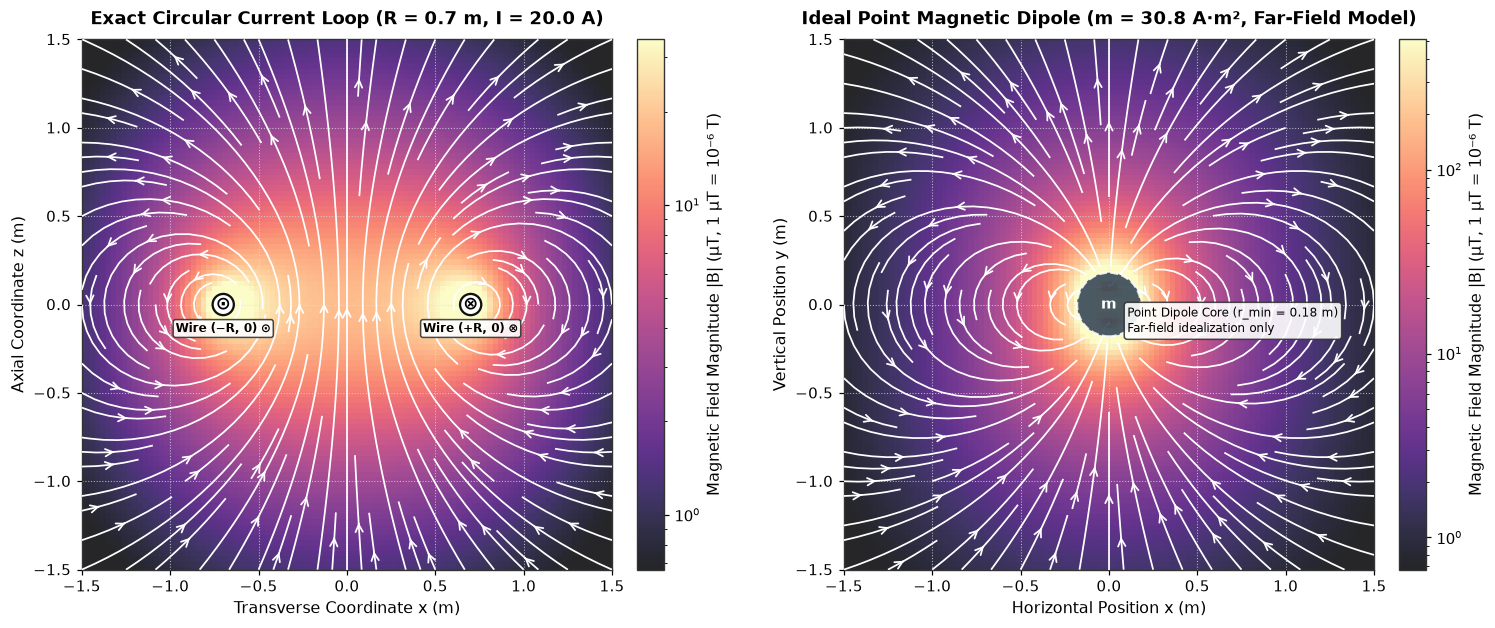

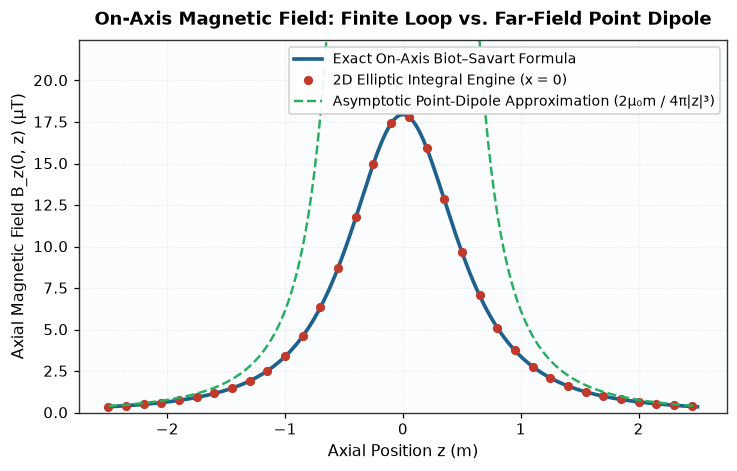

Max relative discrepancy between 2D elliptic integral and exact axial formula: 6.560e-16


In [3]:
R_loop = 0.70
I_loop = 20.0
m_equiv = I_loop * np.pi * (R_loop ** 2)

loop_res = magnetic_field_circular_loop_xz(X, Y, current_amps=I_loop, radius_m=R_loop, r_min=0.06)
dipole_res = magnetic_field_dipole_2d(
    X, Y, dipole_moment_am2=m_equiv, orientation_deg=90.0, r_min=0.18
)

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.6), constrained_layout=True)
plot_magnetic_field_2d(
    loop_res, ax=axes[0], current_amps=I_loop, loop_radius_m=R_loop,
    title=f"Exact Circular Current Loop (R = {R_loop} m, I = {I_loop} A)"
)
plot_magnetic_field_2d(
    dipole_res, ax=axes[1],
    title=f"Ideal Point Magnetic Dipole (m = {m_equiv:.1f} A·m², Far-Field Model)"
)
plt.show()

# Verify on-axis agreement between 2D elliptic-integral solution and exact axial formula
z_axis = np.linspace(-2.5, 2.5, 201)
bz_2d_axis = magnetic_field_circular_loop_xz(np.zeros_like(z_axis), z_axis, current_amps=I_loop, radius_m=R_loop).By
bz_exact_axis = magnetic_field_circular_loop_on_axis(z_axis, current_amps=I_loop, radius_m=R_loop)
bz_dipole_axis = (MU_0 / (4.0 * np.pi)) * (2.0 * m_equiv) / np.maximum(np.abs(z_axis), 0.35) ** 3

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.plot(z_axis, bz_exact_axis * 1e6, "-", lw=2.4, color="#1f618d", label="Exact On-Axis Biot–Savart Formula")
ax.plot(z_axis[::6], bz_2d_axis[::6] * 1e6, "o", color="#c0392b", markersize=5, label="2D Elliptic Integral Engine (x = 0)")
ax.plot(z_axis, bz_dipole_axis * 1e6, "--", lw=1.6, color="#27ae60", label="Asymptotic Point-Dipole Approximation (2μ₀m / 4π|z|³)")
ax.set_xlabel("Axial Position z (m)")
ax.set_ylabel("Axial Magnetic Field B_z(0, z) (μT)")
ax.set_title("On-Axis Magnetic Field: Finite Loop vs. Far-Field Point Dipole")
ax.set_ylim(0, np.max(bz_exact_axis * 1e6) * 1.25)
ax.legend()
plt.show()

rep = verify_circular_loop_on_axis(current_amps=I_loop, radius_m=R_loop)
print(f"Max relative discrepancy between 2D elliptic integral and exact axial formula: {rep['max_relative_error_bz']:.3e}")

### Interpretation
- The 2D elliptic-integral solver agrees with the analytical on-axis Biot–Savart equation to machine precision (relative error $< 10^{-15}$).
- Near the loop center ($|z| < R$), the real loop field is smooth and finite ($B_z(0, 0) = \mu_0 I / (2R) \approx 17.95\ \mu\text{T}$), whereas the point-dipole approximation ($\propto |z|^{-3}$) diverges at $z \to 0$ and only converges to the loop curve for $|z| \gtrsim 2.5 R$. This demonstrates why a point dipole must never be treated as an exact near-field model of a real bar magnet or coil.

---
## 3. Interactive Magnetic Field Explorer

In [4]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))
import numpy as np
import matplotlib.pyplot as plt
from invisible_physics import *

import ipywidgets as widgets
from IPython.display import display


def update_magnetic_lab(
    geometry: str = "Circular Current Loop",
    current_amps: float = 15.0,
    loop_radius_m: float = 0.75,
    dipole_angle_deg: float = 90.0,
) -> None:
    Xg, Yg = create_coordinate_grid((-1.8, 1.8), (-1.8, 1.8), n_points=91)
    if geometry == "Straight Wire":
        res = magnetic_field_straight_wire_2d(Xg, Yg, current_amps=current_amps, r_min=0.06)
        plot_magnetic_field_2d(res, current_amps=current_amps, title=f"Straight Wire (I = {current_amps:+.1f} A)")
    elif geometry == "Circular Current Loop":
        res = magnetic_field_circular_loop_xz(Xg, Yg, current_amps=current_amps, radius_m=loop_radius_m, r_min=0.06)
        plot_magnetic_field_2d(
            res, current_amps=current_amps, loop_radius_m=loop_radius_m,
            title=f"Circular Current Loop (I = {current_amps:+.1f} A, R = {loop_radius_m:.2f} m)"
        )
    else:
        m_val = abs(current_amps) * np.pi * (loop_radius_m ** 2)
        res = magnetic_field_dipole_2d(Xg, Yg, dipole_moment_am2=m_val, orientation_deg=dipole_angle_deg, r_min=0.18)
        plot_magnetic_field_2d(
            res, dipole_orientation_deg=dipole_angle_deg,
            title=f"Point Magnetic Dipole (|m| = {m_val:.1f} A·m², Angle = {dipole_angle_deg:.0f}°)"
        )
    plt.show()


w_geom = widgets.Dropdown(
    options=["Straight Wire", "Circular Current Loop", "Point Magnetic Dipole"],
    value="Circular Current Loop",
    description="Geometry:",
)
w_curr = widgets.FloatSlider(value=15.0, min=-30.0, max=30.0, step=1.0, description="Current I (A):")
w_rad = widgets.FloatSlider(value=0.75, min=0.25, max=1.30, step=0.05, description="Radius R (m):")
w_ang = widgets.FloatSlider(value=90.0, min=0.0, max=360.0, step=15.0, description="Dipole θ (°):")

ui_mag = widgets.HBox([w_geom, w_curr, w_rad, w_ang])
out_mag = widgets.interactive_output(
    update_magnetic_lab,
    {"geometry": w_geom, "current_amps": w_curr, "loop_radius_m": w_rad, "dipole_angle_deg": w_ang},
)
display(ui_mag, out_mag)

Output()

---
## Summary & Further Experiments
- **What we learned**: Steady currents generate divergence-free circulating magnetic fields ($\nabla \cdot \mathbf{B} = 0$) governed by the Biot–Savart law. A long wire decays as $1/r$, while a circular loop transitions from a finite core field $\mu_0 I / (2R)$ at the origin to a $1/r^3$ dipole field at large distances.
- **Next steps**: Proceed to [`04_electromagnetic_wave_lab.ipynb`](04_electromagnetic_wave_lab.ipynb) to study coupled time-varying electric and magnetic fields propagating at the speed of light.